In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ml-100k.zip to ml-100k.zip


In [ ]:
import zipfile
import os

zip_file = "ml-100k.zip"  # ganti sesuai nama file kamu

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [ ]:
os.listdir("dataset")

['ml-100k']

In [ ]:
columns = ['user_id', 'item_id', 'rating', 'timestamp']

df = pd.read_csv('dataset/ml-100k/u.data', sep='\t', names=columns)

item_cols = ['item_id', 'title']
movies = pd.read_csv(
    'dataset/ml-100k/u.item',
    sep='|',
    encoding='latin-1',
    usecols=[0,1],
    names=item_cols
)

In [ ]:
print("\nJumlah missing value:")
print(df.isnull().sum())


Jumlah missing value:
user_id      0
item_id      0
rating       0
timestamp    0
dtype: int64


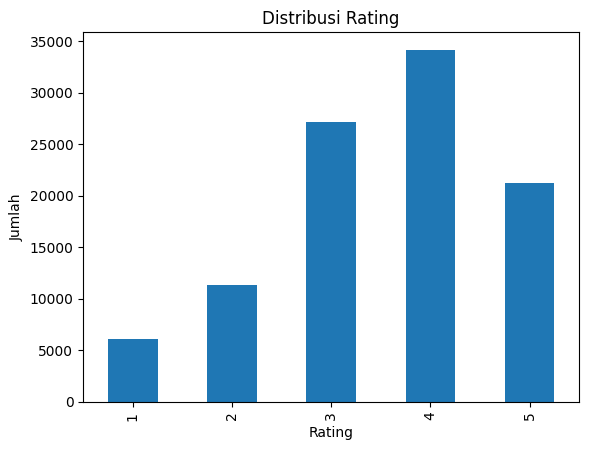

In [ ]:
df['rating'].value_counts().sort_index().plot(kind='bar')
plt.title("Distribusi Rating")
plt.xlabel("Rating")
plt.ylabel("Jumlah")
plt.show()

In [ ]:
# Gabungkan data rating dengan nama film
df = pd.merge(df, movies, on='item_id')

In [ ]:
user_item_matrix = df.pivot_table(index='user_id', columns='title', values='rating')

user_item_matrix = user_item_matrix.fillna(0)

print("\nUser-Item Matrix:")
print(user_item_matrix.head())


User-Item Matrix:
title    'Til There Was You (1997)  1-900 (1994)  101 Dalmatians (1996)  \
user_id                                                                   
1                              0.0           0.0                    2.0   
2                              0.0           0.0                    0.0   
3                              0.0           0.0                    0.0   
4                              0.0           0.0                    0.0   
5                              0.0           0.0                    2.0   

title    12 Angry Men (1957)  187 (1997)  2 Days in the Valley (1996)  \
user_id                                                                 
1                        5.0         0.0                          0.0   
2                        0.0         0.0                          0.0   
3                        0.0         2.0                          0.0   
4                        0.0         0.0                          0.0   
5                

In [ ]:
item_similarity = cosine_similarity(user_item_matrix.T)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

In [ ]:
def recommend_movies(movie_name, top_n=5):
    if movie_name not in item_similarity_df.columns:
        return "Film tidak ditemukan"

    similar_scores = item_similarity_df[movie_name].sort_values(ascending=False)

    # Ambil top-N tanpa dirinya sendiri
    return similar_scores.iloc[1:top_n+1]

In [ ]:
movie_input = "Star Wars (1977)"
print(f"\nRekomendasi untuk: {movie_input}")
print(recommend_movies(movie_input, 5))


Rekomendasi untuk: Star Wars (1977)
title
Return of the Jedi (1983)          0.884476
Raiders of the Lost Ark (1981)     0.764885
Empire Strikes Back, The (1980)    0.749819
Toy Story (1995)                   0.734572
Godfather, The (1972)              0.697332
Name: Star Wars (1977), dtype: float64


In [ ]:
avg_similarity = np.mean(item_similarity)
print("\nRata-rata Similarity:", avg_similarity)


Rata-rata Similarity: 0.08707325705220931


In [ ]:
def recommend_for_user(user_id, top_n=5):
    user_ratings = user_item_matrix.loc[user_id]

    liked_movies = user_ratings[user_ratings > 3].index

    scores = pd.Series(dtype=float)

    for movie in liked_movies:
        scores = scores.add(item_similarity_df[movie], fill_value=0)

    scores = scores.sort_values(ascending=False)

    # Hapus film yang sudah ditonton
    scores = scores.drop(liked_movies, errors='ignore')

    return scores.head(top_n)

# Contoh user-based recommendation
print("\nRekomendasi untuk User 1:")
print(recommend_for_user(1))


Rekomendasi untuk User 1:
title
Forrest Gump (1994)                  67.937816
E.T. the Extra-Terrestrial (1982)    67.053609
Get Shorty (1995)                    65.028279
Fish Called Wanda, A (1988)          64.641377
Dances with Wolves (1990)            63.259763
dtype: float64
